### Exploratory Visualization

In [1]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/utils/")
random_seed = 42

In [ ]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

#### RNA

In [13]:
table_paad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite")
table_paad.sample_metadata["cancer_type"] = "PAAD"
table_chol = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite")
table_chol.sample_metadata["cancer_type"] = "CHOL"
table_stad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite")
table_stad.sample_metadata["cancer_type"] = "STAD"

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite


In [4]:
from sklearn.preprocessing import StandardScaler

def zscore_cohort(table):
    scaler = StandardScaler()
    table_scaled = pd.DataFrame(scaler.fit_transform(table.T).T, index=table.index, columns=table.columns)
    table_scaled = PivotTable(table_scaled)
    table_scaled.feature_metadata = table.feature_metadata
    table_scaled.sample_metadata = table.sample_metadata
    return table_scaled

# 對每個 cohort 分別進行 z-score normalization
table_paad_scaled = zscore_cohort(table_paad)
table_chol_scaled = zscore_cohort(table_chol)
table_stad_scaled = zscore_cohort(table_stad)

In [5]:
rna_table_scaled = PivotTable.merge([table_paad_scaled, table_chol_scaled, table_stad_scaled], join="inner")
rna_table_scaled

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-HU-A4GD-01A,TCGA-VQ-A91A-01A,TCGA-VQ-A94P-01A,TCGA-HU-8608-01A,TCGA-BR-A4J1-01A,TCGA-D7-A6EY-01A,TCGA-VQ-A928-01A,TCGA-FP-7916-01A,TCGA-D7-8570-01A,TCGA-F1-6177-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1BG,0.070368,-0.284744,0.086267,-0.398899,-0.742702,3.806703,-0.070279,-0.430514,-0.424754,0.201081,...,8.232516,-0.023676,0.171846,-0.130622,-0.417032,-0.730607,0.317447,-0.442397,-0.266275,-0.313664
A1CF,0.151914,-0.021317,-0.061099,-0.703070,-0.845950,1.870700,0.042591,-0.839956,-0.638190,-1.316074,...,1.146594,-0.095334,-1.179029,-0.994903,1.105165,-0.644003,-1.176142,0.099231,-0.757418,1.514993
A2M,-1.079846,0.153071,0.284058,-1.071215,-0.757421,-0.013611,0.797572,-0.413637,-1.487022,-0.104247,...,-2.585176,0.975081,1.665667,0.550845,-0.788888,0.242379,0.094608,1.022243,0.449911,-1.143884
A2ML1,-0.608261,-0.672457,-0.697731,0.895686,0.652200,-0.681686,0.993695,0.965244,0.750394,1.689855,...,1.069050,0.664841,-0.405740,-0.406754,-0.434643,-0.169684,-0.427643,-0.422285,-0.336792,-0.451784
A3GALT2,0.504710,-0.341043,-0.981593,1.569374,-0.478357,1.028266,0.807943,-0.404149,-0.981593,-0.981593,...,4.336659,0.637149,-0.659677,0.236242,-0.118248,-0.835757,0.255295,0.524505,-0.110602,-0.620993
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,-0.280797,-0.354041,-0.134854,-0.191201,-0.695891,-0.261818,-0.695891,-0.388331,-0.383281,-0.116139,...,4.090454,-0.584066,-0.703523,0.088569,0.246592,-0.596128,-0.581461,-0.564306,-0.287525,-0.727995
ZYG11B,-0.744273,-1.375955,0.153322,-1.260264,-1.045330,-0.510999,-0.191175,1.198463,-0.831726,-1.428088,...,-0.353790,0.442039,1.866264,0.963729,-0.597682,-0.228978,1.020190,0.271275,-0.684604,-0.229159
ZYX,0.821685,0.035675,0.337402,-0.908903,-0.656937,-1.285771,0.558718,-0.280997,0.232520,1.051353,...,-1.914219,0.895944,1.780161,0.217176,-0.555465,0.476488,0.072529,-0.079493,-0.349521,0.847789


In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

# 移除含 var=0（correlation 無法定義）or NaN 的基因列/樣本欄，避免 correlation 無法計算
rna_scaled_clean = pd.DataFrame(rna_table_scaled).replace([np.inf, -np.inf], np.nan)
rna_scaled_clean = rna_scaled_clean.loc[rna_scaled_clean.notna().all(axis=1), rna_scaled_clean.notna().all(axis=0)]

row_var = rna_scaled_clean.var(axis=1)
col_var = rna_scaled_clean.var(axis=0)
rna_scaled_clean = rna_scaled_clean.loc[row_var > 0, col_var > 0]
print(f"Cleaned matrix shape: {rna_scaled_clean.shape}")
print(f"Removed rows: {(row_var <= 0).sum()}, removed cols: {(col_var <= 0).sum()}")

Cleaned matrix shape: (18659, 561)
Removed rows: 367, removed cols: 0


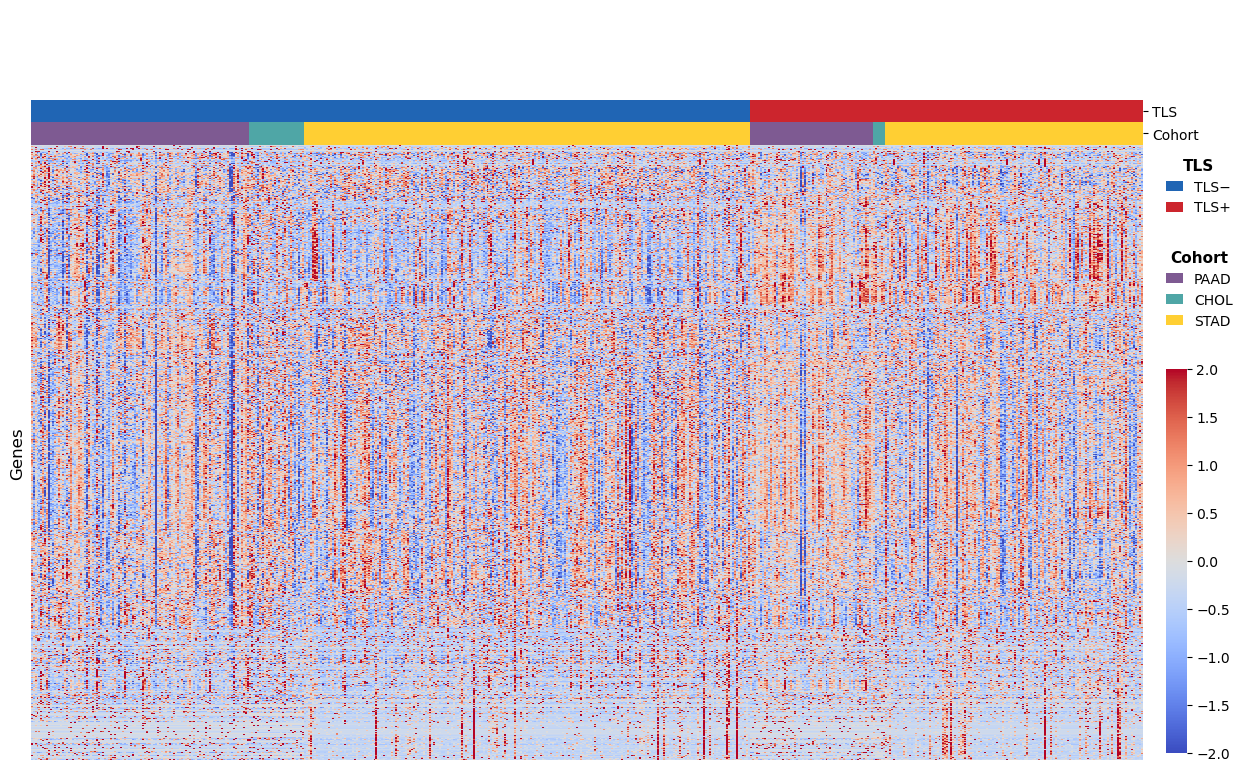

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 依 TLS status 排序欄位，並在同一 TLS 群組內依 cancer type 排序
meta = rna_table_scaled.sample_metadata.loc[rna_scaled_clean.columns, ["TLS", "cancer_type"]].copy()
meta["TLS"] = meta["TLS"].astype(int)
meta["cancer_type"] = pd.Categorical(
    meta["cancer_type"],
    categories=["PAAD", "CHOL", "STAD"],
    ordered=True,
)
sorted_cols = meta.sort_values(["TLS", "cancer_type"]).index
rna_scaled_clean = rna_scaled_clean.loc[:, sorted_cols]

# 提取 TLS 和 cancer type
tls_series = meta.loc[sorted_cols, "TLS"]
cancer_type = meta.loc[sorted_cols, "cancer_type"].astype(str)

# Label Color（依排序後欄位對齊）
tls_palette = {0: "#2065B4", 1: "#CC252D"}
col_colors_tls = tls_series.map(tls_palette)
cancer_palette = {"PAAD": "#7E5A92", "CHOL": "#4FA6A6", "STAD": "#ffcf33"}
col_colors_cancer = cancer_type.map(cancer_palette)

# 合併成 DataFrame（多層 annotation）
col_colors = pd.DataFrame({
    "TLS": col_colors_tls,
    "Cohort": col_colors_cancer
})

# Clustermap
g = sns.clustermap(
    rna_scaled_clean,
    cmap="coolwarm",
    metric="correlation",
    col_colors=col_colors,
    col_cluster=False,
    row_cluster=True,
    figsize=(12, 8),
    dendrogram_ratio=(0.001, 0.12),
    cbar_pos=(0.96, 0.052, 0.017, 0.48),  # (left, bottom, width, height)
    vmax=2,
    vmin=-2,
    xticklabels=False,
    yticklabels=False
)

# 隱藏 row dendrogram
g.ax_row_dendrogram.set_visible(False)

# feature 軸資訊放左邊
g.ax_heatmap.set_xlabel(None)
g.ax_heatmap.set_ylabel("Genes", fontsize=12)
g.ax_heatmap.yaxis.set_label_position("left")
g.ax_heatmap.yaxis.tick_left()

# 用 Patch 製作兩個分開的 legend
handles1 = [
    Patch(facecolor="#2065B4", edgecolor="none", label="TLS−"),
    Patch(facecolor="#CC252D", edgecolor="none", label="TLS+")
]
handles2 = [
    Patch(facecolor="#7E5A92", edgecolor="none", label="PAAD"),
    Patch(facecolor="#4FA6A6", edgecolor="none", label="CHOL"),
    Patch(facecolor="#ffcf33", edgecolor="none", label="STAD")
]

legend1 = g.ax_heatmap.legend(
    handles=handles1,
    title="TLS",
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False,
    handlelength=1.2,
    ncol=1
)
legend1.get_title().set_fontsize(11)
legend1.get_title().set_fontweight("bold")

legend2 = g.ax_heatmap.legend(
    handles=handles2,
    title="Cohort",
    loc="upper left",
    bbox_to_anchor=(1.01, 0.85),   # 向下移動到 y=0.85
    frameon=False,
    handlelength=1.2,
    ncol=1
)
legend2.get_title().set_fontsize(11)
legend2.get_title().set_fontweight("bold")

# 把第一個 legend 加回去（第二個會覆蓋，需要重新添加）
g.ax_heatmap.add_artist(legend1)
plt.savefig("./tiff_figure/paper/clustermap_rna.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

cohort  n_samples  n_features  TLS-  TLS+  silhouette  center_distance  pc1_var  pc2_var
  PAAD        172       19026   110    62    0.037057        34.146067 0.187908 0.138270
  CHOL         34       19026    28     6   -0.099004        13.919537 0.157530 0.091119
  STAD        355       19026   225   130    0.063074        25.975203 0.133916 0.116103


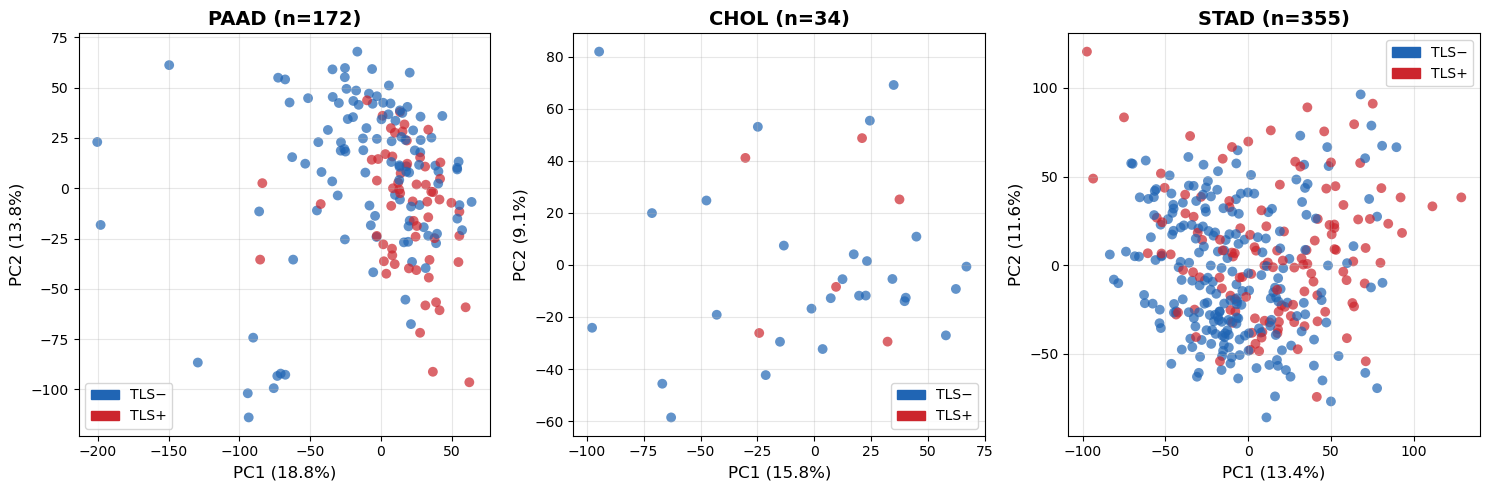

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 每個 cohort 各自使用自己的 feature space，不先做 outer/inner merge
cohort_tables = {'PAAD': table_paad,'CHOL': table_chol,'STAD': table_stad}

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs = axs.flatten()
top_n = 2000
summary_rows = []

# 對每個 cohort 分別計算 PCA
for idx, cohort in enumerate(['PAAD', 'CHOL', 'STAD']):
    ax = axs[idx]
    cohort_data = cohort_tables[cohort]

    # 取該 cohort 自己的 metadata
    meta = cohort_data.sample_metadata.loc[cohort_data.columns]
    tls_cohort = meta['TLS'].astype(int).values

    # # 在 cohort 內選擇 top variance genes
    # gene_vars_cohort = cohort_data.var(axis=1)
    # features_for_pca = gene_vars_cohort.sort_values(ascending=False).head(top_n).index
    # cohort_topn = cohort_data.loc[features_for_pca]
    
    # # 該 cohort 內做 z-score（因為要計算該 cohort 內的 PCA）
    # scaler_cohort = StandardScaler()
    # X_cohort = scaler_cohort.fit_transform(cohort_topn.T).T  # features × samples（轉置回來）

    # 計算 PCA
    pca_cohort = PCA(n_components=2, random_state=42)
    X_samples = cohort_data.T  # samples × features
    pcs_cohort = pca_cohort.fit_transform(X_samples)

    # 計算 TLS 分離程度
    unique_tls = np.unique(tls_cohort)
    if unique_tls.size == 2 and np.min(np.bincount(tls_cohort)) > 1:
        sil = silhouette_score(pcs_cohort, tls_cohort)
        pcs_df = pd.DataFrame(pcs_cohort, columns=['PC1', 'PC2'])
        centers = pcs_df.assign(TLS=tls_cohort).groupby('TLS')[['PC1', 'PC2']].mean()
        center_distance = float(np.linalg.norm(centers.loc[0] - centers.loc[1]))
    else:
        sil = np.nan
        center_distance = np.nan

    summary_rows.append({
        'cohort': cohort,
        'n_samples': int(len(meta)),
        'n_features': int(cohort_data.shape[0]),
        'TLS-': int((tls_cohort == 0).sum()),
        'TLS+': int((tls_cohort == 1).sum()),
        'silhouette': sil,
        'center_distance': center_distance,
        'pc1_var': float(pca_cohort.explained_variance_ratio_[0]),
        'pc2_var': float(pca_cohort.explained_variance_ratio_[1]),
    })

    colors = np.where(tls_cohort == 1, '#CC252D', '#2065B4')
    ax.scatter(pcs_cohort[:, 0], pcs_cohort[:, 1], c=colors, alpha=0.7, s=50, edgecolors='none')

    ax.set_title(f'{cohort} (n={len(meta)})', fontsize=14, fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca_cohort.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
    ax.set_ylabel(f'PC2 ({pca_cohort.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
    ax.grid(alpha=0.3)

    tls_handles = [Patch(color='#2065B4', label='TLS−'), Patch(color='#CC252D', label='TLS+')]
    ax.legend(handles=tls_handles, loc='best', fontsize=10)

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

plt.tight_layout()
plt.savefig("./tiff_figure/paper/PCA_rna.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

cohort  n_samples  n_features  TLS-  TLS+  silhouette  center_distance  pc1_var  pc2_var
  PAAD        172          12   110    62    0.325900         5.489842 0.940804 0.025175
  CHOL         34          12    28     6    0.709101         7.089360 0.933888 0.032660
  STAD        355          12   225   130    0.220813         3.776723 0.866738 0.029250


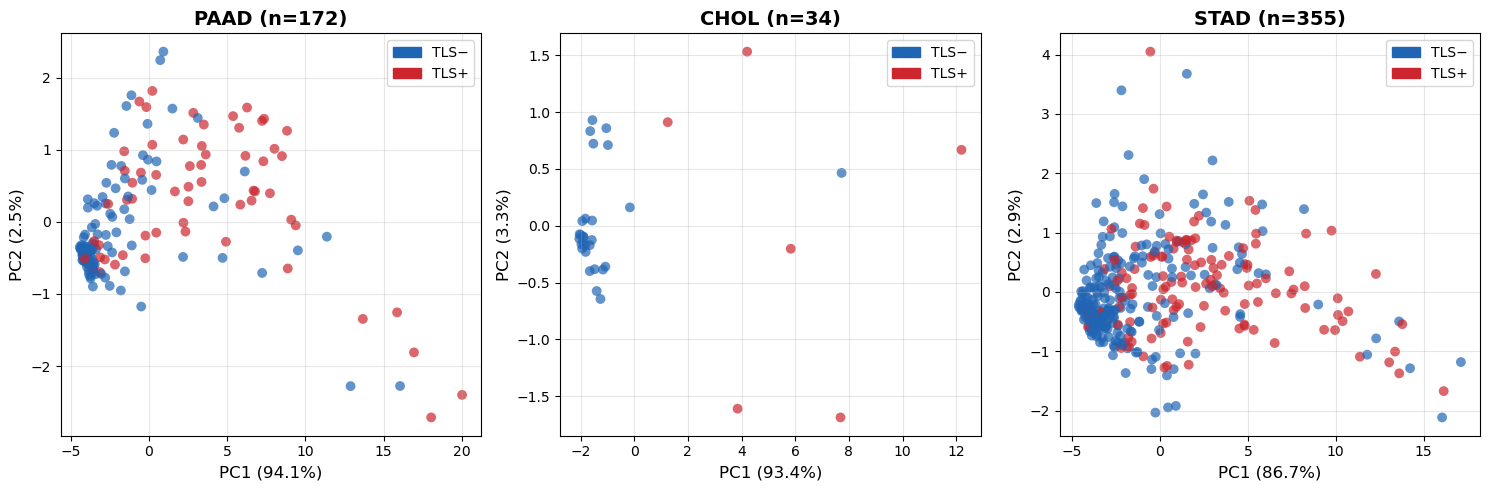

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import re

# 每個 cohort 各自使用自己的 feature space，不先做 outer/inner merge
cohort_tables = {'PAAD': table_paad,'CHOL': table_chol,'STAD': table_stad}
top_features = np.load("/home/data/data_YM313112004/TLS_model/results/all/selected_features/TLS_signatures_across_cancers_42.npy", allow_pickle=True)
consensus_sig = [re.sub("^RNA_", "", g) for g in top_features if g.startswith("RNA_")] 

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs = axs.flatten()
top_n = 2000
summary_rows = []

# 對每個 cohort 分別計算 PCA
for idx, cohort in enumerate(['PAAD', 'CHOL', 'STAD']):
    ax = axs[idx]
    cohort_data = cohort_tables[cohort]
    cohort_data = cohort_data.loc[consensus_sig, :]

    # 取該 cohort 自己的 metadata
    meta = cohort_data.sample_metadata.loc[cohort_data.columns]
    tls_cohort = meta['TLS'].astype(int).values

    # # 在 cohort 內選擇 top variance genes
    # gene_vars_cohort = cohort_data.var(axis=1)
    # features_for_pca = gene_vars_cohort.sort_values(ascending=False).head(top_n).index
    # cohort_topn = cohort_data.loc[features_for_pca]
    
    # # 該 cohort 內做 z-score（因為要計算該 cohort 內的 PCA）
    # scaler_cohort = StandardScaler()
    # X_cohort = scaler_cohort.fit_transform(cohort_topn.T).T  # features × samples（轉置回來）

    # 計算 PCA
    pca_cohort = PCA(n_components=2, random_state=42)
    X_samples = cohort_data.T  # samples × features
    pcs_cohort = pca_cohort.fit_transform(X_samples)

    # 計算 TLS 分離程度
    unique_tls = np.unique(tls_cohort)
    if unique_tls.size == 2 and np.min(np.bincount(tls_cohort)) > 1:
        sil = silhouette_score(pcs_cohort, tls_cohort)
        pcs_df = pd.DataFrame(pcs_cohort, columns=['PC1', 'PC2'])
        centers = pcs_df.assign(TLS=tls_cohort).groupby('TLS')[['PC1', 'PC2']].mean()
        center_distance = float(np.linalg.norm(centers.loc[0] - centers.loc[1]))
    else:
        sil = np.nan
        center_distance = np.nan

    summary_rows.append({
        'cohort': cohort,
        'n_samples': int(len(meta)),
        'n_features': int(cohort_data.shape[0]),
        'TLS-': int((tls_cohort == 0).sum()),
        'TLS+': int((tls_cohort == 1).sum()),
        'silhouette': sil,
        'center_distance': center_distance,
        'pc1_var': float(pca_cohort.explained_variance_ratio_[0]),
        'pc2_var': float(pca_cohort.explained_variance_ratio_[1]),
    })

    colors = np.where(tls_cohort == 1, '#CC252D', '#2065B4')
    ax.scatter(pcs_cohort[:, 0], pcs_cohort[:, 1], c=colors, alpha=0.7, s=50, edgecolors='none')

    ax.set_title(f'{cohort} (n={len(meta)})', fontsize=14, fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca_cohort.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
    ax.set_ylabel(f'PC2 ({pca_cohort.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
    ax.grid(alpha=0.3)

    tls_handles = [Patch(color='#2065B4', label='TLS−'), Patch(color='#CC252D', label='TLS+')]
    ax.legend(handles=tls_handles, loc='best', fontsize=10)

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

plt.tight_layout()
plt.savefig("./tiff_figure/paper/PCA_consensus.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

cohort  n_samples  n_features  TLS-  TLS+  silhouette  center_distance  pc1_var  pc2_var
  PAAD        172          13   110    62    0.316056         5.614687 0.915552 0.026689
  CHOL         34          13    28     6    0.669868         7.292831 0.886100 0.050385
  STAD        355          13   225   130    0.211957         3.815213 0.834326 0.035343


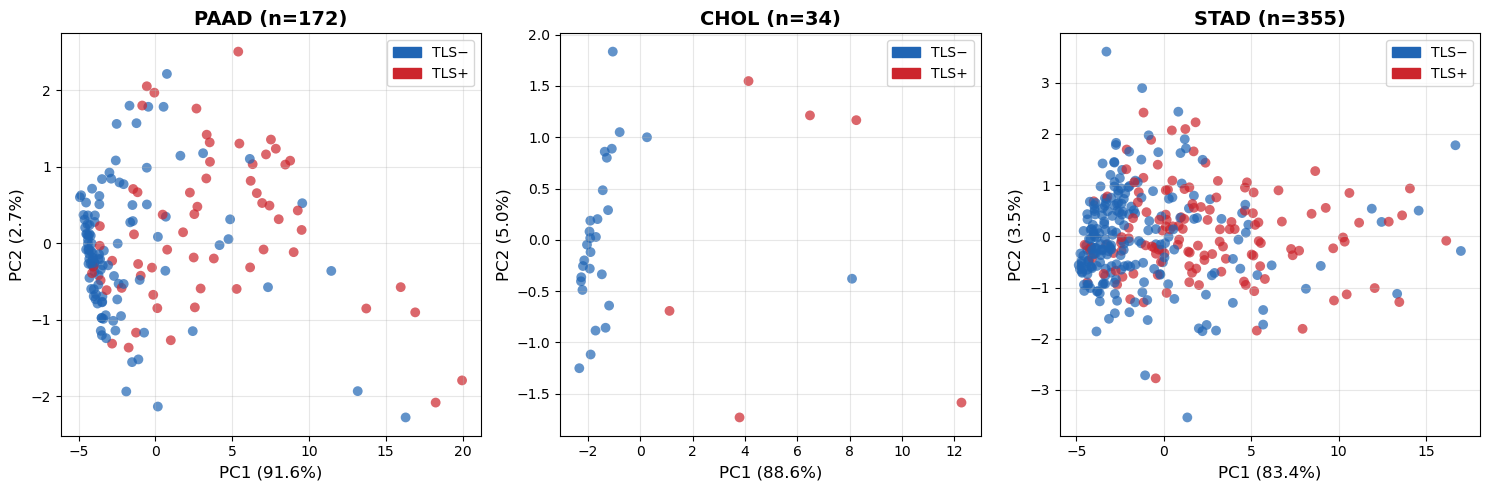

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import re

# 每個 cohort 各自使用自己的 feature space，不先做 outer/inner merge
cohort_tables = {'PAAD': table_paad,'CHOL': table_chol,'STAD': table_stad}
top_features = np.load("/home/data/data_YM313112004/TLS_model/results/all/selected_features/TLS_signatures_42.npy", allow_pickle=True)
pooled_sig = [re.sub("^RNA_", "", g) for g in top_features if g.startswith("RNA_")] 

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs = axs.flatten()
top_n = 2000
summary_rows = []

# 對每個 cohort 分別計算 PCA
for idx, cohort in enumerate(['PAAD', 'CHOL', 'STAD']):
    ax = axs[idx]
    cohort_data = cohort_tables[cohort]
    cohort_data = cohort_data.loc[pooled_sig, :]

    # 取該 cohort 自己的 metadata
    meta = cohort_data.sample_metadata.loc[cohort_data.columns]
    tls_cohort = meta['TLS'].astype(int).values

    # # 在 cohort 內選擇 top variance genes
    # gene_vars_cohort = cohort_data.var(axis=1)
    # features_for_pca = gene_vars_cohort.sort_values(ascending=False).head(top_n).index
    # cohort_topn = cohort_data.loc[features_for_pca]
    
    # # 該 cohort 內做 z-score（因為要計算該 cohort 內的 PCA）
    # scaler_cohort = StandardScaler()
    # X_cohort = scaler_cohort.fit_transform(cohort_topn.T).T  # features × samples（轉置回來）

    # 計算 PCA
    pca_cohort = PCA(n_components=2, random_state=42)
    X_samples = cohort_data.T  # samples × features
    pcs_cohort = pca_cohort.fit_transform(X_samples)

    # 計算 TLS 分離程度
    unique_tls = np.unique(tls_cohort)
    if unique_tls.size == 2 and np.min(np.bincount(tls_cohort)) > 1:
        sil = silhouette_score(pcs_cohort, tls_cohort)
        pcs_df = pd.DataFrame(pcs_cohort, columns=['PC1', 'PC2'])
        centers = pcs_df.assign(TLS=tls_cohort).groupby('TLS')[['PC1', 'PC2']].mean()
        center_distance = float(np.linalg.norm(centers.loc[0] - centers.loc[1]))
    else:
        sil = np.nan
        center_distance = np.nan

    summary_rows.append({
        'cohort': cohort,
        'n_samples': int(len(meta)),
        'n_features': int(cohort_data.shape[0]),
        'TLS-': int((tls_cohort == 0).sum()),
        'TLS+': int((tls_cohort == 1).sum()),
        'silhouette': sil,
        'center_distance': center_distance,
        'pc1_var': float(pca_cohort.explained_variance_ratio_[0]),
        'pc2_var': float(pca_cohort.explained_variance_ratio_[1]),
    })

    colors = np.where(tls_cohort == 1, '#CC252D', '#2065B4')
    ax.scatter(pcs_cohort[:, 0], pcs_cohort[:, 1], c=colors, alpha=0.7, s=50, edgecolors='none')

    ax.set_title(f'{cohort} (n={len(meta)})', fontsize=14, fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca_cohort.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
    ax.set_ylabel(f'PC2 ({pca_cohort.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
    ax.grid(alpha=0.3)

    tls_handles = [Patch(color='#2065B4', label='TLS−'), Patch(color='#CC252D', label='TLS+')]
    ax.legend(handles=tls_handles, loc='best', fontsize=10)

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

plt.tight_layout()
plt.savefig("./tiff_figure/paper/PCA_pooled.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

In [7]:
meth_paad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite")
meth_paad.sample_metadata["cancer_type"] = "PAAD"
meth_chol = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite")
meth_chol.sample_metadata["cancer_type"] = "CHOL"
meth_stad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite")
meth_stad.sample_metadata["cancer_type"] = "STAD"

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite


[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite


cohort  n_samples  n_features  TLS-  TLS+  silhouette  center_distance  pc1_var  pc2_var
  PAAD        172          24   110    62    0.283782         6.522979 0.766277 0.091292
  CHOL         34          38    28     6    0.710109         9.060005 0.787272 0.075800
  STAD        355          16   225   130    0.215448         3.850513 0.841690 0.037543


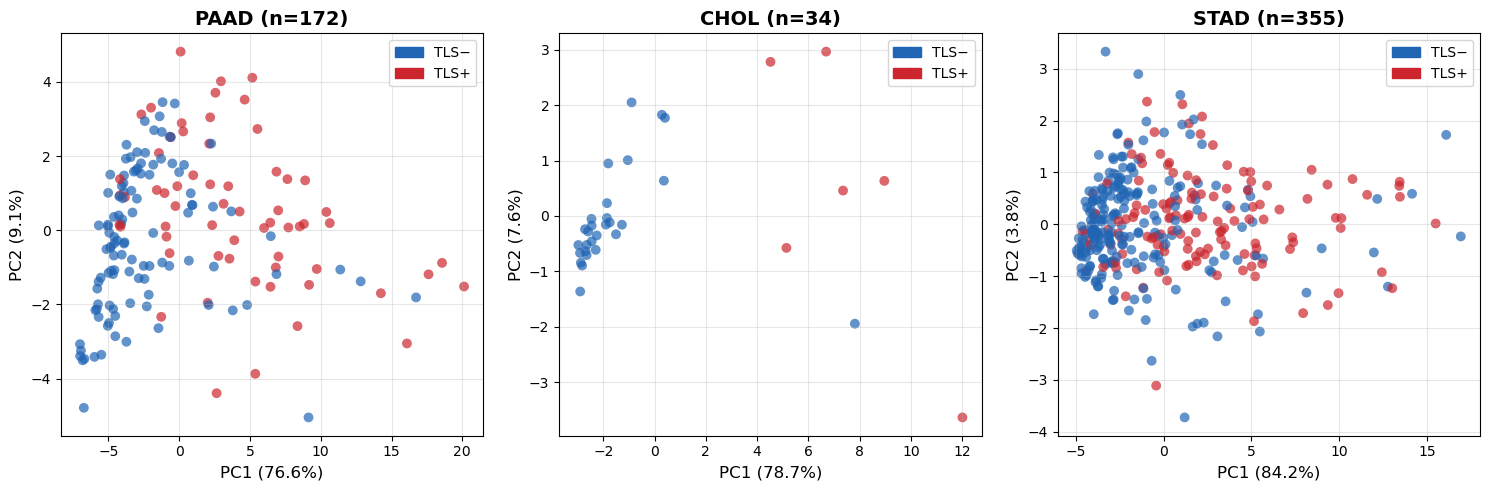

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import re

# 每個 cohort 各自使用自己的 feature space，不先做 outer/inner merge
rna_tables = {'PAAD': table_paad,'CHOL': table_chol,'STAD': table_stad}
meth_tables = {'PAAD': meth_paad,'CHOL': meth_chol,'STAD': meth_stad}

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs = axs.flatten()
top_n = 2000
summary_rows = []

# 對每個 cohort 分別計算 PCA
for idx, cohort in enumerate(['PAAD', 'CHOL', 'STAD']):
    ax = axs[idx]
    top_features = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cohort}/selected_features/TLS_signatures_42.npy", allow_pickle=True)
    rna_sig = [re.sub("^RNA_", "", g) for g in top_features if g.startswith("RNA_")]
    meth_sig = [re.sub("^Meth_", "", g) for g in top_features if g.startswith("Meth_")] 

    rna_data = rna_tables[cohort]
    rna_cohort_data = rna_data.loc[rna_sig, :]
    meth_data = meth_tables[cohort]
    meth_cohort_data = meth_data.loc[meth_sig, :]

    from model_utils import concat_omics
    cohort_data = concat_omics([rna_cohort_data, meth_cohort_data], axis=0)

    # 取該 cohort 自己的 metadata
    meta = cohort_data.sample_metadata.loc[cohort_data.columns]
    tls_cohort = meta['TLS'].astype(int).values

    # # 在 cohort 內選擇 top variance genes
    # gene_vars_cohort = cohort_data.var(axis=1)
    # features_for_pca = gene_vars_cohort.sort_values(ascending=False).head(top_n).index
    # cohort_topn = cohort_data.loc[features_for_pca]
    
    # # 該 cohort 內做 z-score（因為要計算該 cohort 內的 PCA）
    # scaler_cohort = StandardScaler()
    # X_cohort = scaler_cohort.fit_transform(cohort_topn.T).T  # features × samples（轉置回來）

    # 計算 PCA
    pca_cohort = PCA(n_components=2, random_state=42)
    X_samples = cohort_data.T  # samples × features
    pcs_cohort = pca_cohort.fit_transform(X_samples)

    # 計算 TLS 分離程度
    unique_tls = np.unique(tls_cohort)
    if unique_tls.size == 2 and np.min(np.bincount(tls_cohort)) > 1:
        sil = silhouette_score(pcs_cohort, tls_cohort)
        pcs_df = pd.DataFrame(pcs_cohort, columns=['PC1', 'PC2'])
        centers = pcs_df.assign(TLS=tls_cohort).groupby('TLS')[['PC1', 'PC2']].mean()
        center_distance = float(np.linalg.norm(centers.loc[0] - centers.loc[1]))
    else:
        sil = np.nan
        center_distance = np.nan

    summary_rows.append({
        'cohort': cohort,
        'n_samples': int(len(meta)),
        'n_features': int(cohort_data.shape[0]),
        'TLS-': int((tls_cohort == 0).sum()),
        'TLS+': int((tls_cohort == 1).sum()),
        'silhouette': sil,
        'center_distance': center_distance,
        'pc1_var': float(pca_cohort.explained_variance_ratio_[0]),
        'pc2_var': float(pca_cohort.explained_variance_ratio_[1]),
    })

    colors = np.where(tls_cohort == 1, '#CC252D', '#2065B4')
    ax.scatter(pcs_cohort[:, 0], pcs_cohort[:, 1], c=colors, alpha=0.7, s=50, edgecolors='none')

    ax.set_title(f'{cohort} (n={len(meta)})', fontsize=14, fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca_cohort.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
    ax.set_ylabel(f'PC2 ({pca_cohort.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
    ax.grid(alpha=0.3)

    tls_handles = [Patch(color='#2065B4', label='TLS−'), Patch(color='#CC252D', label='TLS+')]
    ax.legend(handles=tls_handles, loc='best', fontsize=10)

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

plt.tight_layout()
plt.savefig("./tiff_figure/paper/PCA_cancer_specific.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

#### Methylation

In [9]:
table_paad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite")
table_paad.sample_metadata["cancer_type"] = "PAAD"
table_chol = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite")
table_chol.sample_metadata["cancer_type"] = "CHOL"
table_stad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite")
table_stad.sample_metadata["cancer_type"] = "STAD"

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite


In [12]:
table_chol.shape, table_paad.shape, table_stad.shape

((146132, 34), (154359, 172), (156220, 355))

In [13]:
from sklearn.preprocessing import StandardScaler

def zscore_cohort(table):
    scaler = StandardScaler()
    table_scaled = pd.DataFrame(scaler.fit_transform(table.T).T, index=table.index, columns=table.columns)
    table_scaled = PivotTable(table_scaled)
    table_scaled.feature_metadata = table.feature_metadata
    table_scaled.sample_metadata = table.sample_metadata
    return table_scaled

# 對每個 cohort 分別進行 z-score normalization
table_paad_scaled = zscore_cohort(table_paad)
table_chol_scaled = zscore_cohort(table_chol)
table_stad_scaled = zscore_cohort(table_stad)

In [14]:
meth_table_scaled = PivotTable.merge([table_paad_scaled, table_chol_scaled, table_stad_scaled], join="inner")
#PivotTable.merge([table_paad_scaled, table_chol_scaled, table_stad_scaled], join="outer")  # 156432 probes
meth_table_scaled

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-HU-A4GD-01A,TCGA-VQ-A91A-01A,TCGA-VQ-A94P-01A,TCGA-HU-8608-01A,TCGA-BR-A4J1-01A,TCGA-D7-A6EY-01A,TCGA-VQ-A928-01A,TCGA-FP-7916-01A,TCGA-D7-8570-01A,TCGA-F1-6177-01A
feature,,,,,,,,,,,,,,,,,,,,,
cg00000029,-1.098800,-0.266993,-0.524632,-0.053324,-0.551476,-0.123006,-0.393820,-1.349030,0.566958,0.487646,...,0.500745,-1.032689,-0.127017,0.775893,-0.183245,0.497126,-0.911055,1.433344,0.687139,-1.577306
cg00000292,0.959618,-0.881232,0.775049,-0.493204,0.686363,1.537680,-0.469343,0.113847,0.007285,-0.076045,...,-1.191593,-0.390174,-0.155780,1.641199,-1.489786,-0.004118,1.042139,1.300419,1.330986,-0.737062
cg00000321,2.605689,-0.441682,0.016674,-0.153704,-1.602951,-1.402976,0.449116,-1.303492,0.653982,-0.542608,...,-0.711184,-1.012378,0.646432,1.249259,-1.921855,-0.584465,-0.511628,0.850444,0.997801,2.238033
cg00000622,-0.044013,-1.238225,-0.202537,0.230111,-0.472806,-1.271626,0.417788,-0.750395,-0.984507,-0.782402,...,2.081001,0.255999,-0.319989,-0.471424,-0.037821,-0.375277,-0.686438,-0.121117,0.019578,-0.772911
cg00000734,0.361659,-1.308383,0.390372,0.509099,-1.171451,0.128748,0.043302,-0.645556,0.712580,0.318223,...,-0.279267,1.144225,-0.190139,0.728278,-2.276404,-1.460066,-0.080976,1.508133,0.118324,-0.195169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ch.3.1075622R,0.004731,-1.125497,-0.368062,0.860711,1.130736,-1.160292,0.553500,-3.355092,-0.392855,0.007075,...,-0.181894,0.248423,-0.263515,-0.452534,-0.192661,-0.422377,-0.238141,1.469528,-0.160455,-0.154202
ch.5.2558853F,-0.281285,-0.172206,0.873742,3.402851,0.925065,-0.769311,-0.238039,-0.881391,-0.404473,-0.237801,...,-0.151009,-0.275044,-0.437272,-0.255306,-0.550436,-0.241318,-0.296733,0.499051,-0.142553,-0.451536
ch.7.3114411F,-0.561653,-0.031061,-0.179954,0.275019,-0.325811,-0.167975,0.273886,-0.508816,-1.033938,0.782876,...,-1.053413,-0.209051,-0.389408,-0.464726,-2.152134,1.193049,-0.990453,0.183008,-0.278412,-0.531658


In [15]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

# 移除含 var=0（correlation 無法定義）or NaN 的基因列/樣本欄，避免 correlation 無法計算
meth_scaled_clean = pd.DataFrame(meth_table_scaled).replace([np.inf, -np.inf], np.nan)
meth_scaled_clean = meth_scaled_clean.loc[meth_scaled_clean.notna().all(axis=1), meth_scaled_clean.notna().all(axis=0)]

row_var = meth_scaled_clean.var(axis=1)
col_var = meth_scaled_clean.var(axis=0)
meth_scaled_clean = meth_scaled_clean.loc[row_var > 0, col_var > 0]
print(f"Cleaned matrix shape: {meth_scaled_clean.shape}")
print(f"Removed rows: {(row_var <= 0).sum()}, removed cols: {(col_var <= 0).sum()}")

Cleaned matrix shape: (145862, 561)
Removed rows: 0, removed cols: 0


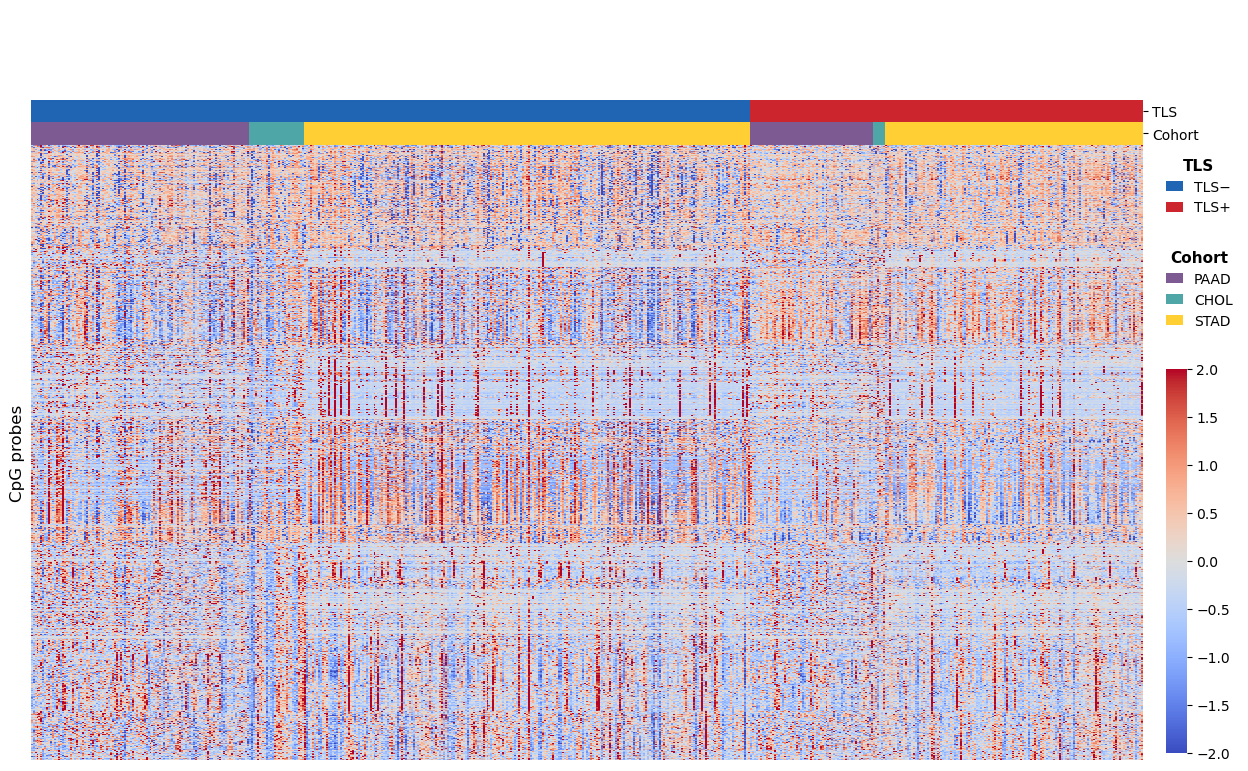

In [16]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 依 TLS status 排序欄位，並在同一 TLS 群組內依 cancer type 排序
meta = meth_table_scaled.sample_metadata.loc[meth_scaled_clean.columns, ["TLS", "cancer_type"]].copy()
meta["TLS"] = meta["TLS"].astype(int)
meta["cancer_type"] = pd.Categorical(
    meta["cancer_type"],
    categories=["PAAD", "CHOL", "STAD"],
    ordered=True,
)
sorted_cols = meta.sort_values(["TLS", "cancer_type"]).index
meth_scaled_clean = meth_scaled_clean.loc[:, sorted_cols]

# 提取 TLS 和 cancer type
tls_series = meta.loc[sorted_cols, "TLS"]
cancer_type = meta.loc[sorted_cols, "cancer_type"].astype(str)

# Label Color（依排序後欄位對齊）
tls_palette = {0: "#2065B4", 1: "#CC252D"}
col_colors_tls = tls_series.map(tls_palette)
cancer_palette = {"PAAD": "#7E5A92", "CHOL": "#4FA6A6", "STAD": "#ffcf33"}
col_colors_cancer = cancer_type.map(cancer_palette)

# 合併成 DataFrame（多層 annotation）
col_colors = pd.DataFrame({
    "TLS": col_colors_tls,
    "Cohort": col_colors_cancer
})

# Clustermap
g = sns.clustermap(
    meth_scaled_clean,
    cmap="coolwarm",
    metric="correlation",
    col_colors=col_colors,
    col_cluster=False,
    row_cluster=True,
    figsize=(12, 8),
    dendrogram_ratio=(0.001, 0.12),
    cbar_pos=(0.96, 0.052, 0.017, 0.48),  # (left, bottom, width, height)
    vmax=2,
    vmin=-2,
    xticklabels=False,
    yticklabels=False
)

# 隱藏 row dendrogram
g.ax_row_dendrogram.set_visible(False)

# feature 軸資訊放左邊
g.ax_heatmap.set_xlabel(None)
g.ax_heatmap.set_ylabel("CpG probes", fontsize=12)
g.ax_heatmap.yaxis.set_label_position("left")
g.ax_heatmap.yaxis.tick_left()

# 用 Patch 製作兩個分開的 legend
from matplotlib.patches import Patch
handles1 = [
    Patch(facecolor="#2065B4", edgecolor="none", label="TLS−"),
    Patch(facecolor="#CC252D", edgecolor="none", label="TLS+")
]
handles2 = [
    Patch(facecolor="#7E5A92", edgecolor="none", label="PAAD"),
    Patch(facecolor="#4FA6A6", edgecolor="none", label="CHOL"),
    Patch(facecolor="#ffcf33", edgecolor="none", label="STAD")
]

legend1 = g.ax_heatmap.legend(
    handles=handles1,
    title="TLS",
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False,
    handlelength=1.2,
    ncol=1
)
legend1.get_title().set_fontsize(11)
legend1.get_title().set_fontweight("bold")

legend2 = g.ax_heatmap.legend(
    handles=handles2,
    title="Cohort",
    loc="upper left",
    bbox_to_anchor=(1.01, 0.85),   # 向下移動到 y=0.85
    frameon=False,
    handlelength=1.2,
    ncol=1
)
legend2.get_title().set_fontsize(11)
legend2.get_title().set_fontweight("bold")

# 把第一個 legend 加回去（第二個會覆蓋，需要重新添加）
g.ax_heatmap.add_artist(legend1)
plt.savefig("./tiff_figure/paper/clustermap_meth.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

cohort  n_samples  n_features  TLS-  TLS+  silhouette  center_distance  pc1_var  pc2_var
  PAAD        172      154359   110    62    0.016539        10.374352 0.235775 0.092422
  CHOL         34      146132    28     6   -0.093798         7.117674 0.240504 0.113844
  STAD        355      156220   225   130    0.006796        10.894149 0.257773 0.128894


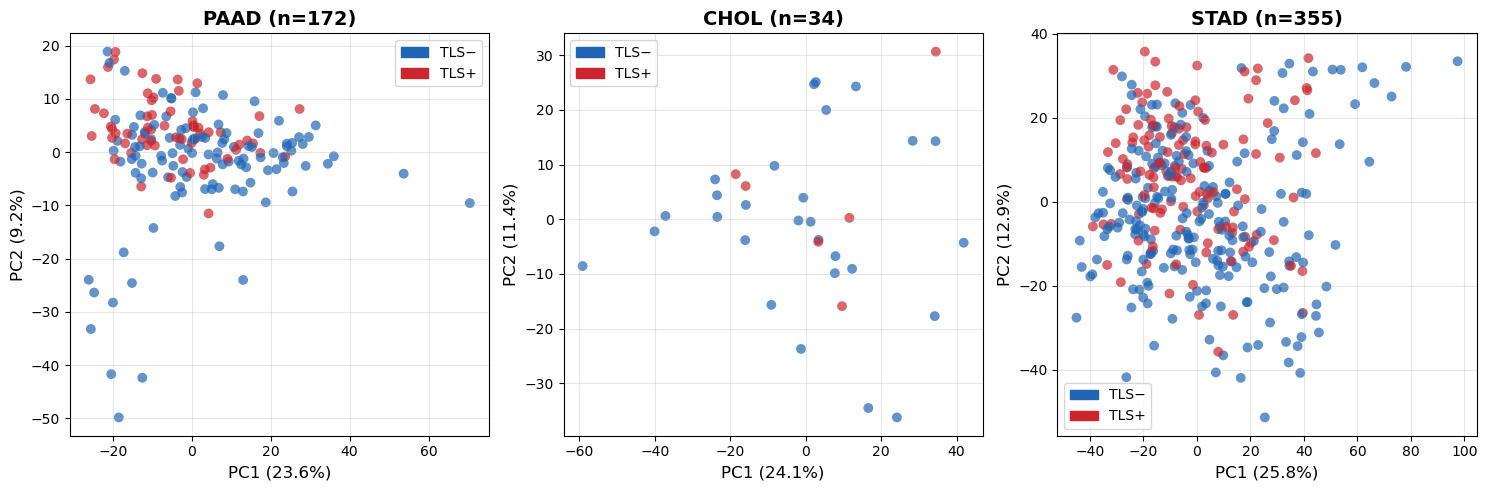

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 每個 cohort 各自使用自己的 feature space，不先做 outer/inner merge
cohort_tables = {'PAAD': meth_paad,'CHOL': meth_chol,'STAD': meth_stad}

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs = axs.flatten()
top_n = 5000
summary_rows = []

# 對每個 cohort 分別計算 PCA
for idx, cohort in enumerate(['PAAD', 'CHOL', 'STAD']):
    ax = axs[idx]
    cohort_data = cohort_tables[cohort]

    # 取該 cohort 自己的 metadata
    meta = cohort_data.sample_metadata.loc[cohort_data.columns]
    tls_cohort = meta['TLS'].astype(int).values

    # # 在 cohort 內選擇 top MAD genes
    # gene_mad_cohort = cohort_data.apply(lambda x: np.median(np.abs(x - np.median(x))), axis=1)
    # features_for_pca = gene_mad_cohort.sort_values(ascending=False).head(top_n).index
    # cohort_topn = cohort_data.loc[features_for_pca]
    
    # # 該 cohort 內做 z-score（因為要計算該 cohort 內的 PCA）
    # scaler_cohort = StandardScaler()
    # X_cohort = scaler_cohort.fit_transform(cohort_topn.T).T  # features × samples（轉置回來）

    # 計算 PCA
    pca_cohort = PCA(n_components=2, random_state=42)
    X_samples = cohort_data.T  # samples × features
    pcs_cohort = pca_cohort.fit_transform(X_samples)

    # 計算 TLS 分離程度
    unique_tls = np.unique(tls_cohort)
    if unique_tls.size == 2 and np.min(np.bincount(tls_cohort)) > 1:
        sil = silhouette_score(pcs_cohort, tls_cohort)
        pcs_df = pd.DataFrame(pcs_cohort, columns=['PC1', 'PC2'])
        centers = pcs_df.assign(TLS=tls_cohort).groupby('TLS')[['PC1', 'PC2']].mean()
        center_distance = float(np.linalg.norm(centers.loc[0] - centers.loc[1]))
    else:
        sil = np.nan
        center_distance = np.nan

    summary_rows.append({
        'cohort': cohort,
        'n_samples': int(len(meta)),
        'n_features': int(cohort_data.shape[0]),
        'TLS-': int((tls_cohort == 0).sum()),
        'TLS+': int((tls_cohort == 1).sum()),
        'silhouette': sil,
        'center_distance': center_distance,
        'pc1_var': float(pca_cohort.explained_variance_ratio_[0]),
        'pc2_var': float(pca_cohort.explained_variance_ratio_[1]),
    })

    colors = np.where(tls_cohort == 1, '#CC252D', '#2065B4')
    ax.scatter(pcs_cohort[:, 0], pcs_cohort[:, 1], c=colors, alpha=0.7, s=50, edgecolors='none')

    ax.set_title(f'{cohort} (n={len(meta)})', fontsize=14, fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca_cohort.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
    ax.set_ylabel(f'PC2 ({pca_cohort.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
    ax.grid(alpha=0.3)

    tls_handles = [Patch(color='#2065B4', label='TLS−'), Patch(color='#CC252D', label='TLS+')]
    ax.legend(handles=tls_handles, loc='best', fontsize=10)

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

plt.tight_layout()
plt.savefig("./tiff_figure/paper/PCA_meth.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

#### Mutation

In [4]:
table_paad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table.sqlite")
table_paad.sample_metadata["cancer_type"] = "PAAD"
table_chol = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/CHOL/table/mutation_table.sqlite")
table_chol.sample_metadata["cancer_type"] = "CHOL"
table_stad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/STAD/table/mutation_table.sqlite")
table_stad.sample_metadata["cancer_type"] = "STAD"

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/mutation_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/mutation_table.sqlite


In [8]:
table_chol.shape, table_paad.shape, table_stad.shape

((1337, 34), (8993, 172), (16100, 355))

#### CNV

In [10]:
table_paad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_table.sqlite")
table_paad.sample_metadata["cancer_type"] = "PAAD"
table_chol = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_table.sqlite")
table_chol.sample_metadata["cancer_type"] = "CHOL"
table_stad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/STAD/table/cnv_table.sqlite")
table_stad.sample_metadata["cancer_type"] = "STAD"

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/cnv_table.sqlite


In [19]:
table_chol.shape, table_paad.shape, table_stad.shape

((17576, 34), (17576, 172), (17576, 355))

In [20]:
cluster_paad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table_42.sqlite")
cluster_paad.sample_metadata["cancer_type"] = "PAAD"
cluster_chol = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_cluster_table_42.sqlite")
cluster_chol.sample_metadata["cancer_type"] = "CHOL"
cluster_stad = PivotTable.read_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/STAD/table/cnv_cluster_table_42.sqlite")
cluster_stad.sample_metadata["cancer_type"] = "STAD"

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table_42.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_cluster_table_42.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/cnv_cluster_table_42.sqlite


In [21]:
cluster_chol.shape, cluster_paad.shape, cluster_stad.shape

((206, 34), (165, 172), (99, 355))

In [22]:
from sklearn.preprocessing import StandardScaler

def zscore_cohort(table):
    scaler = StandardScaler()
    table_scaled = pd.DataFrame(scaler.fit_transform(table.T).T, index=table.index, columns=table.columns)
    table_scaled = PivotTable(table_scaled)
    table_scaled.feature_metadata = table.feature_metadata
    table_scaled.sample_metadata = table.sample_metadata
    return table_scaled

# 對每個 cohort 分別進行 z-score normalization
table_paad_scaled = zscore_cohort(table_paad)
table_chol_scaled = zscore_cohort(table_chol)
table_stad_scaled = zscore_cohort(table_stad)

cluster_paad_scaled = zscore_cohort(cluster_paad)
cluster_chol_scaled = zscore_cohort(cluster_chol)
cluster_stad_scaled = zscore_cohort(cluster_stad)

In [23]:
cnv_table_scaled = PivotTable.merge([table_paad_scaled, table_chol_scaled, table_stad_scaled], join="inner")
cnv_table_scaled

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-HU-A4GD-01A,TCGA-VQ-A91A-01A,TCGA-VQ-A94P-01A,TCGA-HU-8608-01A,TCGA-BR-A4J1-01A,TCGA-D7-A6EY-01A,TCGA-VQ-A928-01A,TCGA-FP-7916-01A,TCGA-D7-8570-01A,TCGA-F1-6177-01A
feature,,,,,,,,,,,,,,,,,,,,,
A1BG,0.026548,0.409375,-0.222092,0.697482,0.030495,0.018655,-0.979852,3.006283,-0.498359,-0.320759,...,1.004251,0.785063,-0.013407,0.637447,0.326558,-0.169970,0.210254,0.972938,0.912550,-0.239305
A1CF,0.174439,1.154381,0.082209,1.154381,-1.958375,-2.725036,-0.759388,-3.526282,0.099502,-0.102250,...,0.463650,-1.182307,0.310725,-0.107807,0.769500,-0.083661,0.584380,-0.059515,-0.043418,-0.309024
A2M,-0.122988,0.451438,-0.960442,0.551207,0.390972,1.597268,0.112829,-0.017173,-0.032290,-0.017173,...,0.499774,0.964366,-0.276930,-0.038677,1.876874,-0.005322,-0.367466,-0.079180,0.047093,-0.093476
A2ML1,-0.122988,0.451438,-0.960442,0.551207,0.390972,1.597268,0.112829,-0.017173,-0.032290,-0.017173,...,0.499774,0.964366,-0.276930,-0.038677,1.876874,-0.005322,-0.367466,-0.079180,0.047093,-0.093476
A3GALT2,-2.307240,-0.639546,0.332883,-0.390567,-1.217367,-2.208587,-0.371776,0.572467,-0.578476,0.539583,...,0.224735,-1.041548,-0.010140,0.035814,1.000844,0.173675,0.107298,0.250265,-0.168425,0.107298
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,-2.476088,-0.718985,0.305579,-0.456657,-1.327784,-2.159315,-0.436859,0.558008,-0.204228,0.523361,...,0.237515,-1.213920,-0.031703,0.020970,1.127104,0.178989,0.102906,0.266778,-0.213132,0.102906
ZYG11B,-2.476088,-0.718985,0.305579,-0.456657,-1.327784,-2.159315,-0.436859,0.558008,-0.204228,0.523361,...,0.237515,-1.213920,-0.031703,0.020970,1.127104,0.178989,0.102906,0.266778,-0.213132,0.102906
ZYX,-0.080546,0.530172,-0.156885,-0.462244,-1.745477,1.649820,-0.145979,-2.766974,-0.164156,-0.382269,...,-0.570053,1.347498,-0.177592,-0.239559,0.328476,-0.225789,-0.508085,-0.174149,0.772577,2.559307


In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch

# 移除含 var=0（correlation 無法定義）or NaN 的基因列/樣本欄，避免 correlation 無法計算
cnv_scaled_clean = pd.DataFrame(cnv_table_scaled).replace([np.inf, -np.inf], np.nan)
cnv_scaled_clean = cnv_scaled_clean.loc[cnv_scaled_clean.notna().all(axis=1), cnv_scaled_clean.notna().all(axis=0)]

row_var = cnv_scaled_clean.var(axis=1)
col_var = cnv_scaled_clean.var(axis=0)
cnv_scaled_clean = cnv_scaled_clean.loc[row_var > 0, col_var > 0]
print(f"Cleaned matrix shape: {cnv_scaled_clean.shape}")
print(f"Removed rows: {(row_var <= 0).sum()}, removed cols: {(col_var <= 0).sum()}")

Cleaned matrix shape: (17576, 561)
Removed rows: 0, removed cols: 0


In [29]:
cnv_table = PivotTable.merge([table_paad, table_chol, table_stad], join="inner")

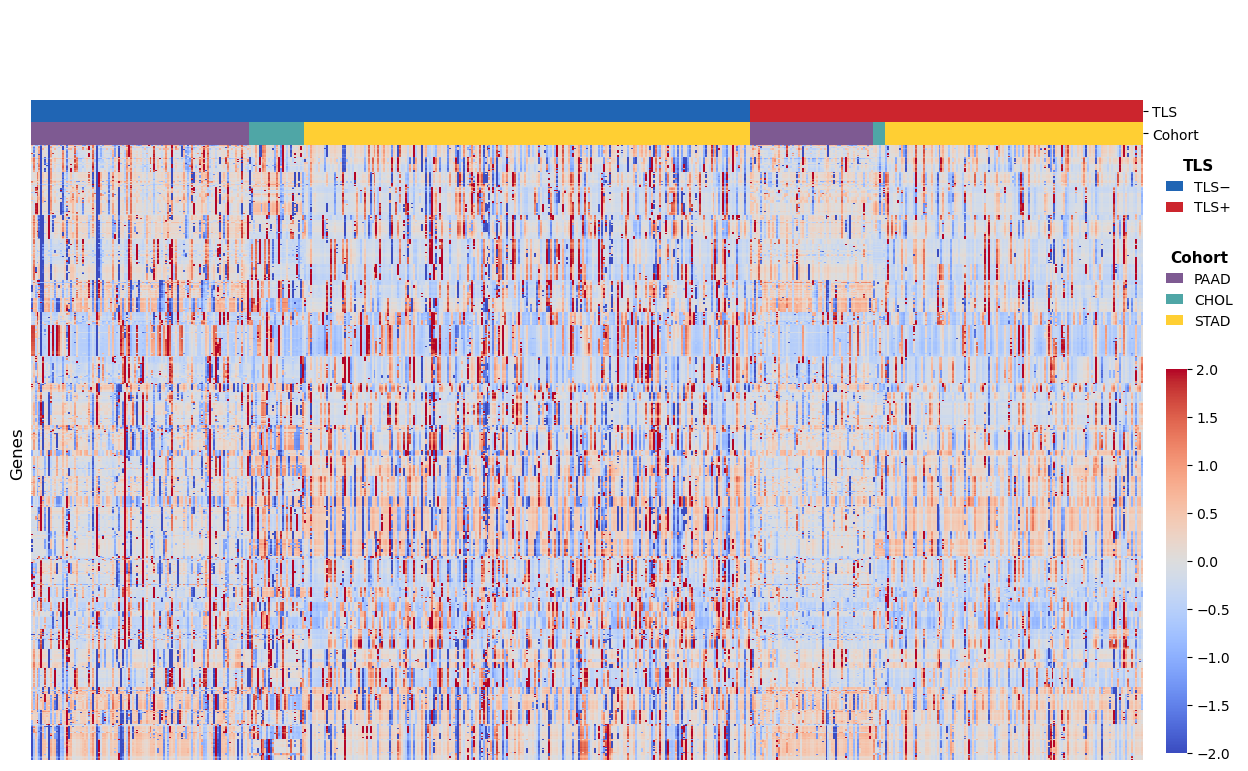

In [27]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 依 TLS status 排序欄位，並在同一 TLS 群組內依 cancer type 排序
meta = cnv_table_scaled.sample_metadata.loc[cnv_scaled_clean.columns, ["TLS", "cancer_type"]].copy()
meta["TLS"] = meta["TLS"].astype(int)
meta["cancer_type"] = pd.Categorical(
    meta["cancer_type"],
    categories=["PAAD", "CHOL", "STAD"],
    ordered=True,
)
sorted_cols = meta.sort_values(["TLS", "cancer_type"]).index
cnv_scaled_clean = cnv_scaled_clean.loc[:, sorted_cols]

# 提取 TLS 和 cancer type
tls_series = meta.loc[sorted_cols, "TLS"]
cancer_type = meta.loc[sorted_cols, "cancer_type"].astype(str)

# Label Color（依排序後欄位對齊）
tls_palette = {0: "#2065B4", 1: "#CC252D"}
col_colors_tls = tls_series.map(tls_palette)
cancer_palette = {"PAAD": "#7E5A92", "CHOL": "#4FA6A6", "STAD": "#ffcf33"}
col_colors_cancer = cancer_type.map(cancer_palette)

# 合併成 DataFrame（多層 annotation）
col_colors = pd.DataFrame({
    "TLS": col_colors_tls,
    "Cohort": col_colors_cancer
})

# Clustermap
g = sns.clustermap(
    cnv_scaled_clean,
    cmap="coolwarm",
    metric="correlation",
    col_colors=col_colors,
    col_cluster=False,
    row_cluster=True,
    figsize=(12, 8),
    dendrogram_ratio=(0.001, 0.12),
    cbar_pos=(0.96, 0.052, 0.017, 0.48),  # (left, bottom, width, height)
    vmax=2,
    vmin=-2,
    xticklabels=False,
    yticklabels=False
)

# 隱藏 row dendrogram
g.ax_row_dendrogram.set_visible(False)

# feature 軸資訊放左邊
g.ax_heatmap.set_xlabel(None)
g.ax_heatmap.set_ylabel("Genes", fontsize=12)
g.ax_heatmap.yaxis.set_label_position("left")
g.ax_heatmap.yaxis.tick_left()

# 用 Patch 製作兩個分開的 legend
from matplotlib.patches import Patch
handles1 = [
    Patch(facecolor="#2065B4", edgecolor="none", label="TLS−"),
    Patch(facecolor="#CC252D", edgecolor="none", label="TLS+")
]
handles2 = [
    Patch(facecolor="#7E5A92", edgecolor="none", label="PAAD"),
    Patch(facecolor="#4FA6A6", edgecolor="none", label="CHOL"),
    Patch(facecolor="#ffcf33", edgecolor="none", label="STAD")
]

legend1 = g.ax_heatmap.legend(
    handles=handles1,
    title="TLS",
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    frameon=False,
    handlelength=1.2,
    ncol=1
)
legend1.get_title().set_fontsize(11)
legend1.get_title().set_fontweight("bold")

legend2 = g.ax_heatmap.legend(
    handles=handles2,
    title="Cohort",
    loc="upper left",
    bbox_to_anchor=(1.01, 0.85),   # 向下移動到 y=0.85
    frameon=False,
    handlelength=1.2,
    ncol=1
)
legend2.get_title().set_fontsize(11)
legend2.get_title().set_fontweight("bold")

# 把第一個 legend 加回去（第二個會覆蓋，需要重新添加）
g.ax_heatmap.add_artist(legend1)
plt.savefig("./tiff_figure/paper/clustermap_cnv.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

cohort  n_samples  n_features  TLS-  TLS+  silhouette  center_distance  pc1_var  pc2_var
  PAAD        172       17576   110    62   -0.055652         5.582179 0.257818 0.074966
  CHOL         34       17576    28     6   -0.193822         6.382629 0.289482 0.089348
  STAD        355       17576   225   130    0.003776         6.397079 0.120259 0.046899


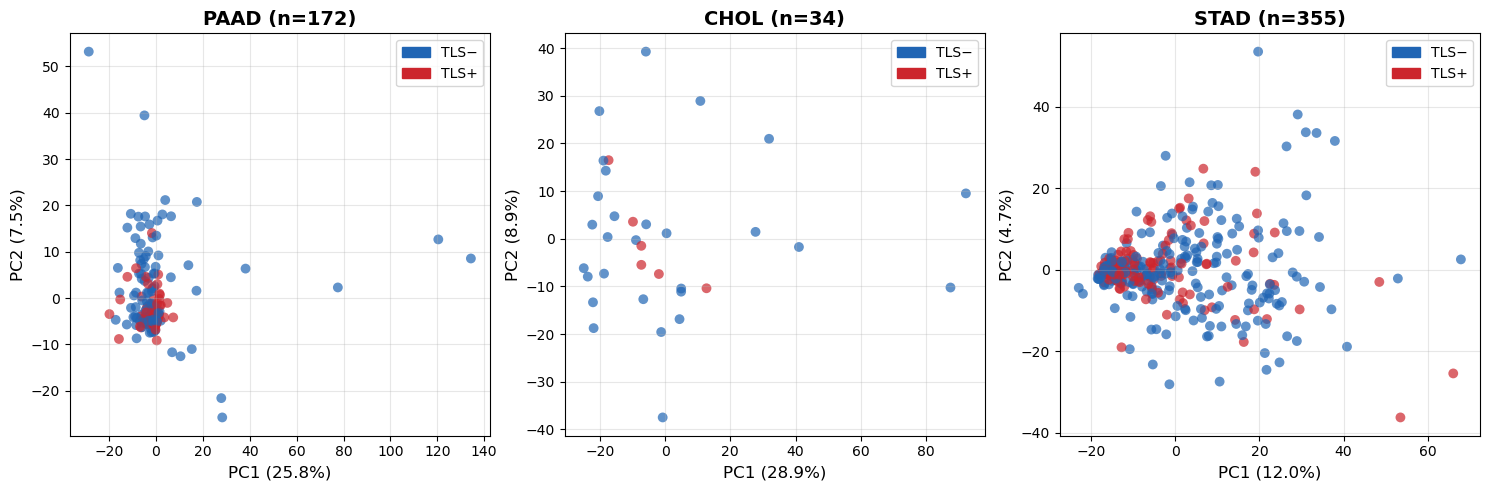

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 每個 cohort 各自使用自己的 feature space，不先做 outer/inner merge
cohort_tables = {'PAAD': table_paad,'CHOL': table_chol,'STAD': table_stad}

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs = axs.flatten()
top_n = 2000
summary_rows = []

# 對每個 cohort 分別計算 PCA
for idx, cohort in enumerate(['PAAD', 'CHOL', 'STAD']):
    ax = axs[idx]
    cohort_data = cohort_tables[cohort]

    # 取該 cohort 自己的 metadata
    meta = cohort_data.sample_metadata.loc[cohort_data.columns]
    tls_cohort = meta['TLS'].astype(int).values

    # # 在 cohort 內選擇 top variance genes
    # gene_vars_cohort = cohort_data.var(axis=1)
    # features_for_pca = gene_vars_cohort.sort_values(ascending=False).head(top_n).index
    # cohort_topn = cohort_data.loc[features_for_pca]
    
    # # 該 cohort 內做 z-score（因為要計算該 cohort 內的 PCA）
    # scaler_cohort = StandardScaler()
    # X_cohort = scaler_cohort.fit_transform(cohort_topn.T).T  # features × samples（轉置回來）

    # 計算 PCA
    pca_cohort = PCA(n_components=2, random_state=42)
    X_samples = cohort_data.T  # samples × features
    pcs_cohort = pca_cohort.fit_transform(X_samples)

    # 計算 TLS 分離程度
    unique_tls = np.unique(tls_cohort)
    if unique_tls.size == 2 and np.min(np.bincount(tls_cohort)) > 1:
        sil = silhouette_score(pcs_cohort, tls_cohort)
        pcs_df = pd.DataFrame(pcs_cohort, columns=['PC1', 'PC2'])
        centers = pcs_df.assign(TLS=tls_cohort).groupby('TLS')[['PC1', 'PC2']].mean()
        center_distance = float(np.linalg.norm(centers.loc[0] - centers.loc[1]))
    else:
        sil = np.nan
        center_distance = np.nan

    summary_rows.append({
        'cohort': cohort,
        'n_samples': int(len(meta)),
        'n_features': int(cohort_data.shape[0]),
        'TLS-': int((tls_cohort == 0).sum()),
        'TLS+': int((tls_cohort == 1).sum()),
        'silhouette': sil,
        'center_distance': center_distance,
        'pc1_var': float(pca_cohort.explained_variance_ratio_[0]),
        'pc2_var': float(pca_cohort.explained_variance_ratio_[1]),
    })

    colors = np.where(tls_cohort == 1, '#CC252D', '#2065B4')
    ax.scatter(pcs_cohort[:, 0], pcs_cohort[:, 1], c=colors, alpha=0.7, s=50, edgecolors='none')

    ax.set_title(f'{cohort} (n={len(meta)})', fontsize=14, fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca_cohort.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
    ax.set_ylabel(f'PC2 ({pca_cohort.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
    ax.grid(alpha=0.3)

    tls_handles = [Patch(color='#2065B4', label='TLS−'), Patch(color='#CC252D', label='TLS+')]
    ax.legend(handles=tls_handles, loc='best', fontsize=10)

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

plt.tight_layout()
plt.savefig("./tiff_figure/paper/PCA_cnv.tiff", dpi=300, format='tiff', bbox_inches="tight", pil_kwargs={'compression': 'tiff_lzw'})
plt.show()